# Assignment 4 Classification 

#### Imports

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


#### Import the dataset

In [34]:
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


## Data Preprocessing

#### Handle Missing Values

In [35]:
#inspect data set
print("Dataset Shape:", df.shape)
print(df.dtypes)
print(df.isna().sum())

Dataset Shape: (303, 14)
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


#### Dataset descrption

In [36]:
df.describe()
df["target"].value_counts()

target
1    165
0    138
Name: count, dtype: int64

### Check for Class Imbalance 

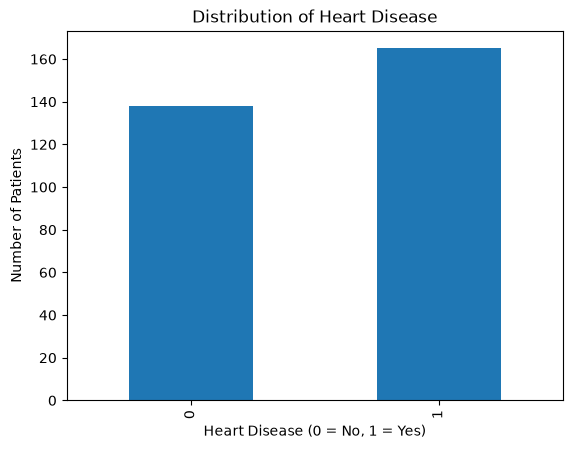

In [37]:
df["target"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Patients")
plt.show()

### Split the Data

In [38]:
from sklearn.model_selection import train_test_split

#get features and target
X = df.drop(columns="target")
y = df["target"]

#split the data into 80% training data and 20% testing data
X_train, X_Test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=.2, 
                                                    random_state=42, 
                                                    stratify=y) #maintains the same proportion of patients with and without heart disease

print("Training size:", X_train.shape)
print("Testing size:", X_Test.shape)

Training size: (242, 13)
Testing size: (61, 13)


## Feature Engineering

#### Plot age distribution

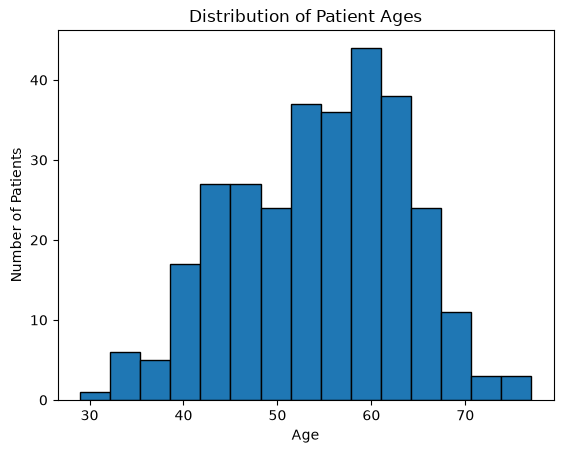

In [39]:
#creating a histogram of the distributions of ages in the dataset
plt.hist(df["age"], bins=15, edgecolor="black")
plt.title("Distribution of Patient Ages")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

#### Plot cholesterol distribution

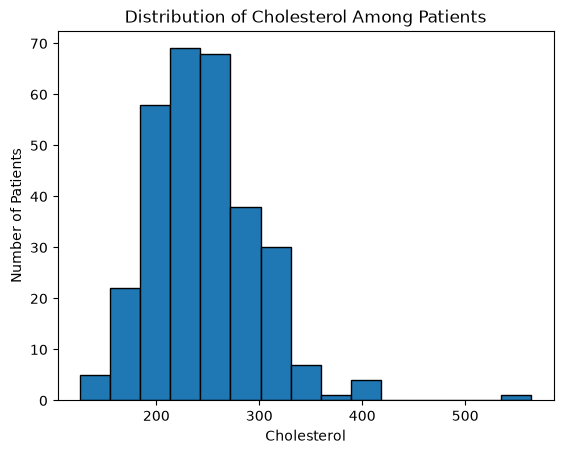

In [40]:
#creating a distribution of the cholesterol levels among the patients in the dataset
plt.hist(df["chol"], bins=15, edgecolor="black")
plt.title("Distribution of Cholesterol Among Patients")
plt.xlabel("Cholesterol")
plt.ylabel("Number of Patients")
plt.show()

#### Calculate feature correlations with the target

In [41]:
correlations = df.corr(numeric_only=True)["target"].sort_values(
    ascending=False
)

print(correlations)

target      1.000000
cp          0.433798
thalach     0.421741
slope       0.345877
restecg     0.137230
fbs        -0.028046
chol       -0.085239
trestbps   -0.144931
age        -0.225439
sex        -0.280937
thal       -0.344029
ca         -0.391724
oldpeak    -0.430696
exang      -0.436757
Name: target, dtype: float64


#### Plot the correlations with only the continuous columns

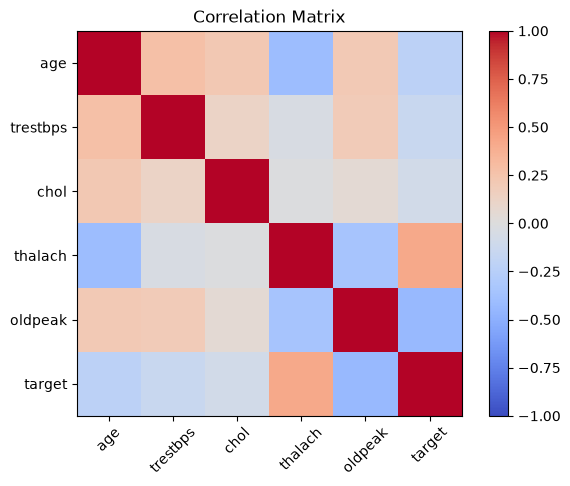

In [42]:
#some non-continuous variables like "cp"(chestpain) will throw off the correlation so we will plot the correlation
continuous_cols = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

#creating the correlation matrix
correlation_matrix = df[continuous_cols + ["target"]].corr()

#creating the figure
plt.figure(figsize=(7,5))
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()

#making the ticks the column names and rotating the x ticks so they can all fit
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=45)
plt.yticks(range(len(correlation_matrix.columns)), correlation_matrix.columns)

plt.title("Correlation Matrix")
plt.show()

#### One hot encoding for the categorical features

In [46]:
categorical_cols = ["cp", "restecg", "slope", "thal"]

#one hot encoding for training X data 
X_train_encoded = pd.get_dummies(
    X_train, 
    columns=categorical_cols, 
    dtype=int
)
#one hot encoding for the testing X data
X_Test_encoded = pd.get_dummies(
    X_Test, 
    columns=categorical_cols,
    dtype=int
)

#testing to make sure all the columns match for training and testing
X_Test_encoded = X_Test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

print("Before encoding:", X_train.shape)
print("After encoding:", X_train_encoded.shape)

Before encoding: (242, 13)
After encoding: (242, 23)


#### Standardize numerical features 

In [47]:
from sklearn.preprocessing import StandardScaler

#columns to standardize
numeric_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]

#create copies so the encoded data remains unchanged
X_train_scaled = X_train_encoded.copy()
X_test_scaled = X_Test_encoded.copy()

#create standard scalar this performs z-score normalization
scaler = StandardScaler()

X_train_scaled[numeric_cols] = scaler.fit_transform(
    X_train_encoded[numeric_cols]
)

X_test_scaled[numeric_cols] = scaler.transform(
    X_Test_encoded[numeric_cols]
)

X_train_scaled.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_0,...,restecg_0,restecg_1,restecg_2,slope_0,slope_1,slope_2,thal_0,thal_1,thal_2,thal_3
19,1.610480,0,0.461840,-0.123235,0,0.039942,0,0.604853,2,0,...,0,1,0,0,0,1,0,0,1,0
247,1.282051,1,1.575595,0.023366,0,-1.373486,1,-0.890458,3,0,...,0,1,0,0,1,0,0,1,0,0
289,0.077810,0,-0.206413,-0.835301,0,-0.917541,1,0.770998,1,1,...,0,0,1,0,1,0,0,0,0,1
288,0.296763,1,-1.208792,1.887302,0,-0.324813,1,1.601727,1,1,...,0,1,0,0,1,0,0,0,0,1
60,1.829433,0,-1.208792,0.421285,1,-0.917541,0,-0.890458,1,0,...,1,0,0,0,0,1,0,0,1,0


#### Feature selection

In [48]:
from sklearn.feature_selection import SelectKBest, f_classif

#create feature selector to keep the 10 best features
selector = SelectKBest(score_func=f_classif, k=10)

#fit selector on training data only 
X_train_selected = selector.fit_transform(X_train_scaled, y_train)

#apply same thing to the testing data
X_test_selected = selector.transform(X_test_scaled)

#display selected feature names
selected_features = X_train_scaled.columns[selector.get_support()]

print(selected_features)

Index(['thalach', 'exang', 'oldpeak', 'ca', 'cp_0', 'cp_2', 'slope_1',
       'slope_2', 'thal_2', 'thal_3'],
      dtype='str')


## Model Training 

#### Train Logistic Regression Model With all Features

In [52]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

#create the logistic regression model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

#fit the model with all features 
lr_model.fit(X_train_scaled, y_train)

#predict on testing data
y_lr_predict = lr_model.predict(X_test_scaled)

#calculate accuracy score
lr_accuracy = accuracy_score(y_test, y_lr_predict)

print(f"Accuracy: {lr_accuracy}")

Accuracy: 0.8032786885245902


#### Train Logistic Regression Model With Only Selected Features

In [54]:
#create the logistic regression model for the selected features
lr_selected = LogisticRegression(max_iter=1000, random_state=42)

#fit the model
lr_selected.fit(X_train_selected, y_train)

#create prediction
y_predict = lr_selected.predict(X_test_selected)

#calculate the accuracy score
lr_selected_accuracy = accuracy_score(y_test, y_predict)

print(f"Accuracy: {lr_selected_accuracy}")

Accuracy: 0.8524590163934426


#### Train Gaussian Naive Bayes Model